# D03 — Économétrie de la moyenne | B06 — GLD (exposition à l’or)

## Objectif du livrable

**Question étudiée :** les rendements passés de GLD permettent-ils de prévoir son **rendement de la séance suivante**, mieux qu’une méthode naïve ?

Pour répondre, nous suivons une démarche classique **Box–Jenkins** :
1. calculer les rendements et vérifier leur **stationnarité (test ADF)** ;
2. examiner les graphiques **ACF/PACF** pour proposer des modèles **ARIMA(p,d,q)** simples ;
3. estimer **ARIMA classique**, puis tester **Auto-ARIMA** en complément et comparer les deux approches avec **naïf, SARIMA et SARIMAX** ;
4. évaluer les erreurs sur des dates non utilisées pour l’apprentissage et présenter des **prévisions datées**.

**Découpage temporel du D02 :**

| Jeu | Période | Rôle |
|---|---|---|
| Apprentissage | 2018–2022 | Stationnarité, ACF/PACF et estimation |
| Validation | 2023–2024 | Comparaison et choix du modèle |
| Test final | 01/01/2025–30/10/2026 | Évaluation du modèle retenu |

**Important :** D03 porte sur la *moyenne* des rendements, pas sur la rentabilité d’une stratégie. La comparaison exposition fixe / exposition dynamique avec GARCH appartient aux étapes suivantes du projet B06.

*Installation si nécessaire :* `pip install pmdarima statsmodels pandas numpy matplotlib jupyter`

## 1. Charger les données D02

Nous reprenons le **snapshot GLD de D02** pour travailler sur les mêmes données que le reste du projet. La colonne `Close` sert à calculer les rendements, tandis que `Volume` sera testé comme variable complémentaire dans SARIMAX.

Nous contrôlons les dates, les doublons et les valeurs manquantes avant de commencer.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

# Fonctionne depuis la racine du dépôt ou depuis notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
snapshots = sorted((ROOT / "data" / "raw").glob("GLD_*/GLD_daily.csv"))
if not snapshots:
    raise FileNotFoundError("Snapshot GLD absent. Depuis la racine du projet, exécuter : python -m src.data")

fichier = snapshots[-1]
df = pd.read_csv(fichier, parse_dates=["Date"]).set_index("Date").sort_index()
df = df.loc["2018-01-01":"2026-10-30", ["Close", "Volume"]].copy()

if df.index.has_duplicates or df.isna().any().any() or (df["Close"] <= 0).any() or (df["Volume"] < 0).any():
    raise ValueError("Données à vérifier avec l'audit D02 avant de continuer.")

print("Snapshot :", fichier.relative_to(ROOT))
print("Séances :", len(df), "| Du", df.index.min().date(), "au", df.index.max().date())
df.head()

Snapshot : data\raw\GLD_20261115T154114487177Z\GLD_daily.csv
Séances : 2220 | Du 2018-01-02 au 2026-10-30


,Close,Volume
Date,,
2018-01-02,125.150002,11762500
2018-01-03,124.820000,7904300
2018-01-04,125.459999,7329700
2018-01-05,125.330002,5739900
2018-01-08,125.309998,3566700


## 2. Construire la série à prévoir

Nous modélisons le **rendement logarithmique quotidien en pourcentage**, plutôt que le prix, car l’objectif de D03 est d’étudier la moyenne des variations d’un jour à l’autre :

$ r_t = 100 \times \ln\!\left(\frac{Close_t}{Close_{t-1}}\right) $

Pour SARIMAX, nous utilisons la variation du log-volume **retardée d’une séance** : cette information est déjà connue lorsque l’on prévoit le rendement du jour suivant.

Enfin, les données sont séparées **chronologiquement** afin d’éviter de tester le modèle sur des observations déjà utilisées pour l’estimer.

In [3]:
df["rendement"] = 100 * np.log(df["Close"] / df["Close"].shift(1))
df["volume_retarde"] = np.log1p(df["Volume"]).diff().shift(1)
df = df.dropna()

train = df.loc[:"2022-12-31"]
validation = df.loc["2023-01-01":"2024-12-31"]
test = df.loc["2025-01-01":"2026-10-30"]

assert len(train) > 500 and len(validation) > 100 and len(test) > 100
print("Train :", len(train), "| Validation :", len(validation), "| Test :", len(test))
print("Cible : rendement quotidien GLD (%)")

Train : 1257 | Validation : 502 | Test : 459
Cible : rendement quotidien GLD (%)


### Graphique 1 — Évolution du prix de GLD

Ce graphique donne le **contexte économique** de l’étude. La prévision porte néanmoins sur les *rendements*, non sur le prix lui-même.

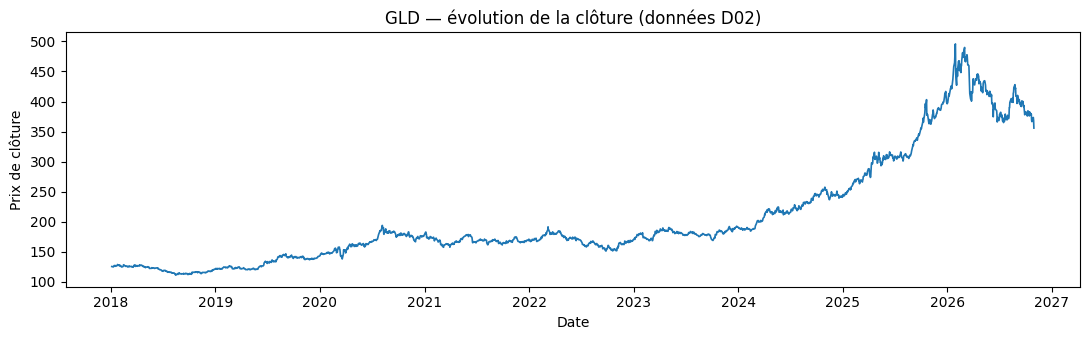

In [4]:
plt.figure(figsize=(11, 3.5))
plt.plot(df.index, df["Close"], linewidth=1.2)
plt.title("GLD — évolution de la clôture (données D02)")
plt.ylabel("Prix de clôture")
plt.xlabel("Date")
plt.tight_layout()
plt.show()

## 3. Vérifier la stationnarité — test ADF

**Pourquoi ?** La méthode ARIMA demande de déterminer combien de différenciations (`d`) sont nécessaires pour rendre la série suffisamment stable dans le temps.

Le **test ADF** vérifie la présence d’une racine unitaire :
- **p-value < 0,05** : on rejette l’hypothèse de racine unitaire ; nous retenons **d = 0**.
- **p-value ≥ 0,05** : on ne peut pas la rejeter ; nous essayons **d = 1**.

Nous effectuons le test **uniquement sur les rendements d’apprentissage (2018–2022)**. Le seuil de 5 % est une règle pratique, pas une certitude statistique.

In [5]:
y_train = train["rendement"].reset_index(drop=True)
x_train = train["volume_retarde"].reset_index(drop=True)

adf_stat, adf_pvalue, *_ = adfuller(y_train, autolag="AIC")
d = 0 if adf_pvalue < 0.05 else 1
print(f"ADF sur le train : statistique = {adf_stat:.3f} | p-value = {adf_pvalue:.4g}")
print(f"Différenciation retenue : d = {d}")
print("Interprétation :", "rendements stationnaires selon ADF au seuil de 5 %." if d == 0
      else "stationnarité non confirmée ; on utilise une différenciation.")

# Cette série est utilisée pour lire l'ACF/PACF ; ARIMA effectue lui-même d si besoin.
y_stationnaire = y_train if d == 0 else y_train.diff().dropna()

ADF sur le train : statistique = -15.423 | p-value = 3.021e-28
Différenciation retenue : d = 0
Interprétation : rendements stationnaires selon ADF au seuil de 5 %.


C:\Users\ilyas\AppData\Local\Temp\ipykernel_14196\3334678605.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_pvalue, *_ = adfuller(y_train, autolag="AIC")


## 4. Étudier l'ACF et la PACF — choisir p et q

**Pourquoi ces graphiques ?** Ils indiquent comment les rendements restent liés aux séances précédentes et aident à proposer des ordres simples :

- **ACF** : corrélations avec les retards ; un pic isolé peut suggérer une partie **MA(q)**.
- **PACF** : corrélations directes après contrôle des retards intermédiaires ; un pic isolé peut suggérer une partie **AR(p)**.
- Les bandes autour de zéro correspondent approximativement à un seuil de **95 %**. Les pics hors bande sont des *indices*, pas des preuves définitives.

On analyse **seulement la série d'apprentissage**, stationnaire ou différenciée selon l’ADF. Nous évitons de chercher des ordres élevés sans raison.

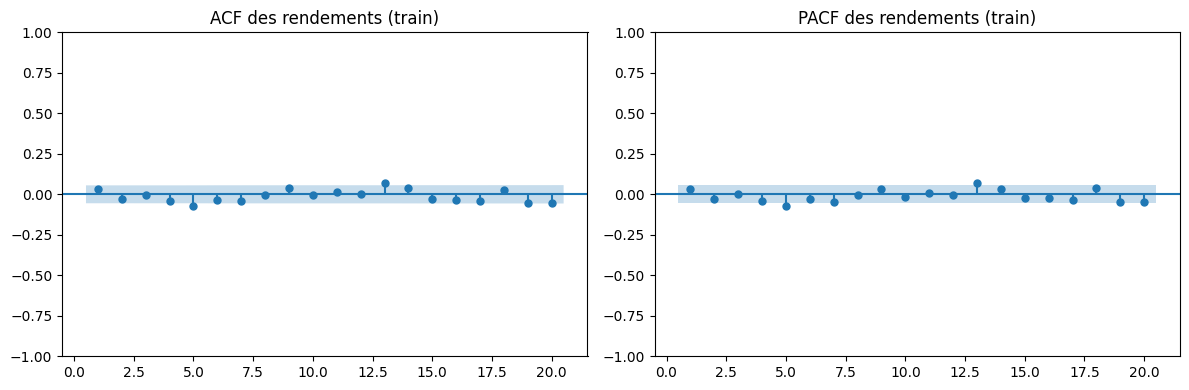

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(y_stationnaire, lags=20, ax=axes[0], zero=False)
plot_pacf(y_stationnaire, lags=20, ax=axes[1], zero=False, method="ywm")
axes[0].set_title("ACF des rendements (train)")
axes[1].set_title("PACF des rendements (train)")
plt.tight_layout()
plt.show()

### 4.1 — Chercher une saisonnalité dans les rendements de GLD

Est-ce que certains mois de l’année ont tendance à mieux performer que d’autres ?
Nous calculons les rendements mensuels sur la période d’apprentissage 2018–2022.
Nous utilisons ensuite une décomposition STL avec un cycle de 12 mois pour
visualiser le motif saisonnier et nous examinons les rendements de janvier année par année.

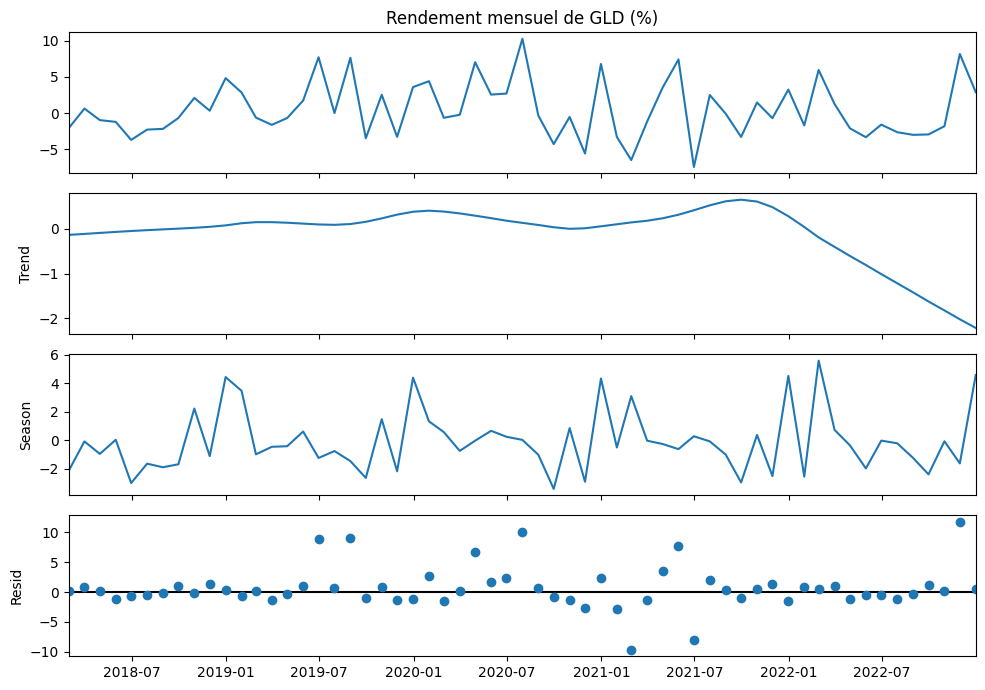

Date
2019-01-31    2.85
2020-01-31    4.40
2021-01-31   -3.28
2022-01-31   -1.69


In [21]:
from statsmodels.tsa.seasonal import STL

# Calculer le rendement entre la dernière clôture d'un mois et celle du mois précédent
clotures = train["Close"].resample(pd.offsets.MonthEnd()).last()
rendements_mensuels = (100 * np.log(clotures / clotures.shift(1))).dropna()
rendements_mensuels.name = "Rendement mensuel de GLD (%)"

# Chercher un motif qui se répète tous les 12 mois
decomposition = STL(rendements_mensuels, period=12, robust=True).fit()
fig = decomposition.plot()
fig.set_size_inches(10, 7)
fig.tight_layout()
plt.show()

# Lire les rendements réellement observés en janvier
janviers = rendements_mensuels[rendements_mensuels.index.month == 1]
print(janviers.round(2).to_string())

### Interprétation de la décomposition STL de GLD (2018–2022)

- Les **rendements mensuels** alternent entre hausses et baisses, avec des variations allant d’environ −7 % à +10 %.
- La **tendance (`Trend`)** du rendement reste proche de zéro ou légèrement positive pendant une grande partie de la période, puis devient négative en 2022.
- La **composante saisonnière (`Season`)** montre des pics positifs qui reviennent vers la fin de plusieurs années. Cela suggère un possible effet de fin d’année.
- Les **résidus (`Resid`)** montrent que certains mois s’écartent fortement de ce que la tendance et la saisonnalité expliquent.

**Que peut-on conclure ?** Nous avons demandé à STL de chercher un cycle de 12 mois. Le motif visible est donc un indice à vérifier sur d’autres années. Pour janvier en particulier, nous observons deux hausses et deux baisses sur les quatre mois de janvier complets. Ces données ne suffisent pas à établir un effet janvier régulier.

## 5. Identifier un ARIMA(p,d,q) classique

Plutôt que de lancer une recherche automatique, nous examinons **quatre hypothèses courtes** cohérentes avec les interprétations habituelles des graphiques :

| Modèle candidat | Justification |
|---|---|
| ARIMA(0,d,0) | Référence sans dépendance temporelle |
| ARIMA(1,d,0) | Une dépendance de type **AR**, suggérée par la PACF |
| ARIMA(0,d,1) | Une dépendance de type **MA**, suggérée par l’ACF |
| ARIMA(1,d,1) | Effets AR et MA possibles simultanément |

**Démarche traditionnelle :** ces ordres sont des **candidats choisis explicitement**, que l’on peut adapter après lecture des ACF/PACF. Nous comparons leur **AIC calculé sur le train seulement** : un AIC plus faible indique un compromis ajustement/complexité plus favorable *dans cet ensemble de candidats*. La MAE en validation restera le critère pour choisir entre les **familles** de modèles.

In [7]:
# Ordres courts proposés à partir de l'ACF/PACF ; modifiables après inspection.
candidats = [(0, d, 0), (1, d, 0), (0, d, 1), (1, d, 1)]
trend = "c" if d == 0 else "n"  # pas de constante de niveau si d=1

essais = []
modeles_arima = {}
for ordre in candidats:
    resultat = ARIMA(y_train, order=ordre, trend=trend).fit()
    modeles_arima[ordre] = resultat
    essais.append({"Ordre": str(ordre), "AIC (train)": resultat.aic,
                   "BIC (train)": resultat.bic})

tableau_arima = pd.DataFrame(essais).sort_values("AIC (train)")
display(tableau_arima.round(2))
ordre_arima = min(modeles_arima, key=lambda ordre: modeles_arima[ordre].aic)
print(f"ARIMA retenu parmi les hypothèses testées : {ordre_arima} (plus petit AIC sur le train).")

,Ordre,AIC (train),BIC (train)
0,"(0, 0, 0)",3321.38,3331.65
2,"(0, 0, 1)",3321.68,3337.09
1,"(1, 0, 0)",3321.77,3337.18
3,"(1, 0, 1)",3322.88,3343.42


ARIMA retenu parmi les hypothèses testées : (0, 0, 0) (plus petit AIC sur le train).


## 6. Estimer les modèles à comparer

- **Naïf** : prévoit le rendement de la veille. Il constitue la référence minimale.
- **ARIMA classique** : utilise l’ordre `(p,d,q)` obtenu par **ADF + ACF/PACF + comparaison AIC**.
- **SARIMA** : reprend cet ordre et teste en plus une **saisonnalité hypothétique de 5 séances** (une semaine boursière).
- **SARIMAX** : reprend le même ordre ARIMA et ajoute le **volume retardé** pour mesurer son éventuel intérêt.

L’**Auto-ARIMA** sera ajouté juste après comme méthode complémentaire de sélection automatique des ordres. Les modèles sont tous estimés sur **2018–2022 uniquement**. Cette comparaison permet de vérifier si l'ajout de complexité apporte vraiment quelque chose.

In [8]:
ajustes = {"ARIMA": modeles_arima[ordre_arima]}
modeles = {
    "SARIMA": SARIMAX(y_train, order=ordre_arima, seasonal_order=(1, 0, 0, 5),
                      trend=trend),
    "SARIMAX": SARIMAX(y_train, exog=x_train, order=ordre_arima, trend=trend),
}
for nom, modele in modeles.items():
    ajustes[nom] = modele.fit(disp=False)
    print(f"{nom} entraîné.")

SARIMA entraîné.
SARIMAX entraîné.


### Résumé statistique de l’ARIMA choisi

Le `summary()` présente les **coefficients estimés**, leurs p-values et les indicateurs **AIC/BIC**. Il sert à **décrire et vérifier** le modèle ARIMA identifié ; il ne prouve pas à lui seul que les prévisions futures seront bonnes.

In [9]:
print(f"=== ARIMA{ordre_arima} : résumé statistique (apprentissage uniquement) ===")
print(ajustes["ARIMA"].summary())

=== ARIMA(0, 0, 0) : résumé statistique (apprentissage uniquement) ===
                               SARIMAX Results                                
Dep. Variable:              rendement   No. Observations:                 1257
Model:                          ARIMA   Log Likelihood               -1658.690
Date:                Fri, 20 Nov 2026   AIC                           3321.379
Time:                        11:15:53   BIC                           3331.652
Sample:                             0   HQIC                          3325.240
                               - 1257                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0244      0.026      0.945      0.344      -0.026       0.075
sigma2         0.8198      0.020     41.583      0.000      

### Complément — Auto-ARIMA : vérifier le choix de (p, d, q)

Nous gardons **l’ARIMA classique identifié grâce à l’ADF, à l’ACF/PACF et à l’AIC**.

En complément, **Auto-ARIMA** teste automatiquement quelques ordres simples et retient celui qui minimise l'**AIC sur l’apprentissage uniquement** (2018–2022). Cela permet de confronter notre choix manuel à une méthode automatique, **sans utiliser la validation ni le test pour l’ajustement**.

Le `summary()` affiche l’ordre retenu, les coefficients et les indicateurs du modèle. **Le meilleur AIC n’implique pas nécessairement la meilleure prévision** : nous départagerons les modèles avec la MAE de validation.

In [10]:
from pmdarima import auto_arima

# Recherche volontairement limitée pour rester simple et rapide.
auto_modele = auto_arima(
    y_train,
    seasonal=False,
    stepwise=True,
    start_p=0, start_q=0,
    max_p=2, max_q=2, max_d=1,
    information_criterion="aic",
    suppress_warnings=True,
    error_action="ignore",
)

ordre_auto = auto_modele.order
print(f"Auto-ARIMA : ordre retenu = {ordre_auto}")
print(f"ARIMA classique : ordre retenu = {ordre_arima}")
print("\n=== Résumé statistique d'Auto-ARIMA (train seulement) ===")
print(auto_modele.summary())

# Même format de résultats que les autres modèles pour la comparaison datée.
ajustes["Auto-ARIMA"] = auto_modele.arima_res_


Auto-ARIMA : ordre retenu = (0, 0, 0)
ARIMA classique : ordre retenu = (0, 0, 0)

=== Résumé statistique d'Auto-ARIMA (train seulement) ===
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1257
Model:                        SARIMAX   Log Likelihood               -1659.146
Date:                Fri, 20 Nov 2026   AIC                           3320.293
Time:                        11:16:03   BIC                           3325.429
Sample:                             0   HQIC                          3322.223
                               - 1257                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         0.8203      0.020     41.874      0.000       0.782    

## 7. Produire des prédictions datées, sans fuite temporelle

Pour chaque séance de **validation** et de **test**, nous calculons une prévision **un jour à l’avance**.

Les **coefficients restent fixés** après l’entraînement. Au fil des dates, seules les observations déjà connues sont utilisées pour mettre à jour l’historique : le rendement à prévoir n'est jamais fourni au modèle au moment de le prédire.

Nous conservons les **dates, valeurs réelles et prévisions** pour pouvoir vérifier la méthode.

In [11]:
y = df["rendement"].reset_index(drop=True)
x = df["volume_retarde"].reset_index(drop=True)
premiere_prediction = len(train)

previsions = pd.DataFrame(index=df.index[premiere_prediction:])
previsions.index.name = "Date"
previsions["Réel"] = df["rendement"].iloc[premiere_prediction:]
previsions["Naïf"] = df["rendement"].shift(1).iloc[premiere_prediction:]

for nom, resultat in ajustes.items():
    # apply réutilise les paramètres du train, mais filtre les observations
    # dans leur ordre chronologique ; information_set='predicted' = 1 pas avant.
    filtre = resultat.apply(y, exog=x if nom == "SARIMAX" else None, refit=False)
    pred = filtre.get_prediction(start=premiere_prediction, end=len(df) - 1,
                                information_set="predicted").predicted_mean
    previsions[nom] = np.asarray(pred)

previsions["Période"] = np.where(previsions.index.year <= 2024, "Validation", "Test")
previsions.head()

,Réel,Naïf,ARIMA,SARIMA,SARIMAX,Auto-ARIMA,Période
Date,,,,,,,
2023-01-03,0.833582,0.466776,0.024403,0.004143,0.023438,0.0,Validation
2023-01-04,0.936789,0.833582,0.024403,-0.035463,0.030783,0.0,Validation
2023-01-05,-1.252963,0.936789,0.024403,0.059216,0.024069,0.0,Validation
2023-01-06,1.853466,-1.252963,0.024403,-0.014841,0.021427,0.0,Validation
2023-01-09,0.224260,1.853466,0.024403,-0.008132,0.027633,0.0,Validation


## 8. Comparer les performances

Nous comparons également **ARIMA classique et Auto-ARIMA** sur exactement les mêmes dates. Nous mesurons les écarts entre rendement réel et prédit :
- **MAE** : erreur absolue moyenne ; facile à interpréter.
- **RMSE** : pénalise davantage les grandes erreurs.

Les scores s’expriment en **points de pourcentage de rendement**. **Plus faible = meilleur.** Nous sélectionnons le modèle sur la **validation 2023–2024**, puis nous regardons le test 2025–2026 sans modifier la sélection.

In [12]:
noms = ["Naïf", "ARIMA", "Auto-ARIMA", "SARIMA", "SARIMAX"]
lignes = []
for nom in noms:
    ligne = {"Modèle": nom}
    for periode in ["Validation", "Test"]:
        part = previsions[previsions["Période"] == periode]
        erreur = part["Réel"] - part[nom]
        ligne[f"MAE {periode}"] = erreur.abs().mean()
        ligne[f"RMSE {periode}"] = np.sqrt((erreur ** 2).mean())
    lignes.append(ligne)

scores = pd.DataFrame(lignes).set_index("Modèle")
meilleur = scores["MAE Validation"].idxmin()
print("Modèle sélectionné sur la validation :", meilleur)
display(scores.round(4))

Modèle sélectionné sur la validation : ARIMA


,MAE Validation,RMSE Validation,MAE Test,RMSE Test
Modèle,,,,
Naïf,0.9854,1.2824,1.7155,2.2849
ARIMA,0.6800,0.8963,1.1441,1.5924
Auto-ARIMA,0.6814,0.8979,1.1471,1.5935
SARIMA,0.6866,0.9007,1.1487,1.5999
SARIMAX,0.6802,0.8963,1.1441,1.5925


### Graphique 2 — Comparaison des MAE

Un modèle ne doit pas être choisi parce qu'il est plus complexe : ce graphique montre directement s’il réduit **réellement l’erreur** par rapport à la méthode naïve.

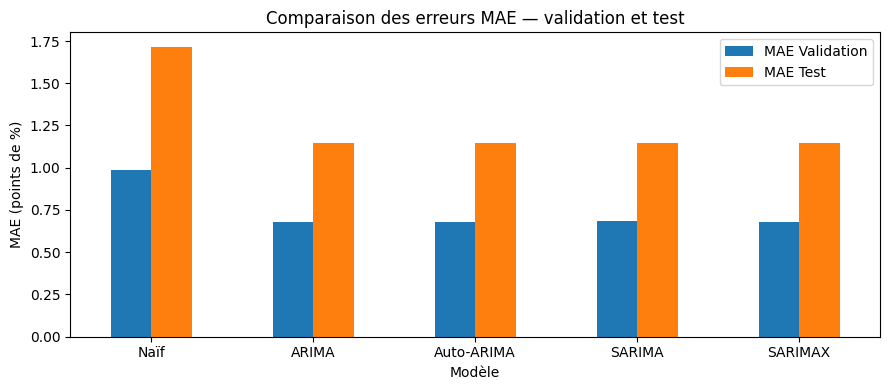

In [13]:
ax = scores[["MAE Validation", "MAE Test"]].plot(kind="bar", figsize=(9, 4), rot=0)
ax.set_title("Comparaison des erreurs MAE — validation et test")
ax.set_ylabel("MAE (points de %)")
ax.set_xlabel("Modèle")
plt.tight_layout()
plt.show()

## 9. Vérifier les résidus et visualiser les prédictions

Les **résidus** sont les erreurs commises pendant l’ajustement. Pour un ARIMA satisfaisant, ils ne devraient pas présenter d’autocorrélation marquée.

Le **test de Ljung–Box** (10 retards) complète la lecture de l’**ACF des résidus** :
- **p-value ≥ 0,05** : pas d’autocorrélation détectée à ce seuil ;
- **p-value < 0,05** : il reste probablement une structure à expliquer.

Les deux derniers graphiques comparent **réel et prédit** sur les 60 dernières séances de validation et de test. Une courbe prévisionnelle presque plate est possible : les rendements journaliers peuvent être difficiles à prévoir.

,Ljung–Box p-value (train)
Modèle,
ARIMA,0.0675
SARIMA,0.4416
SARIMAX,0.0671
Auto-ARIMA,0.0675


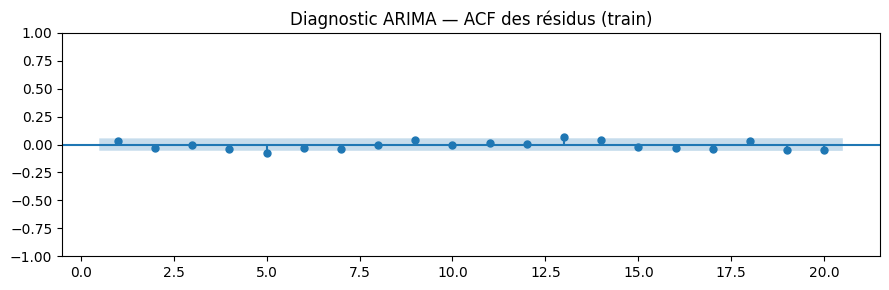

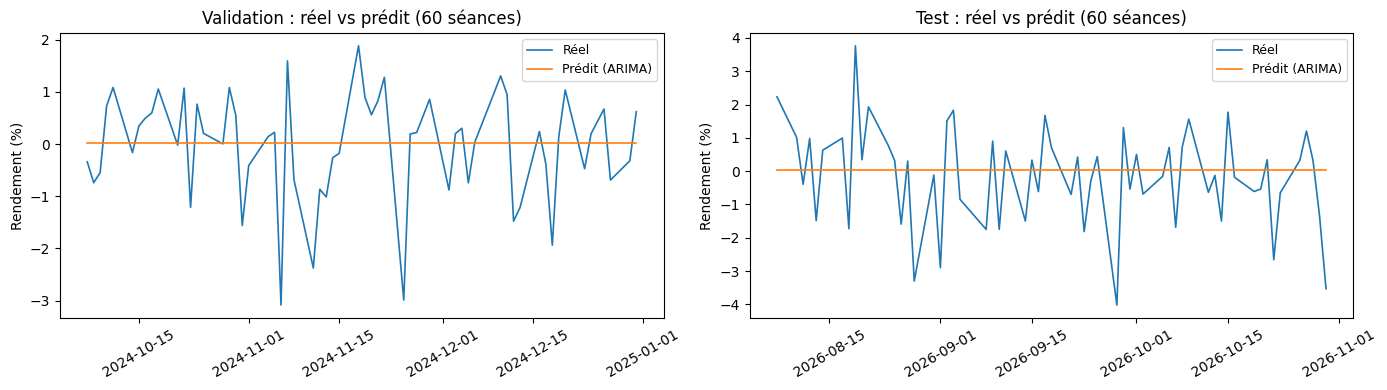

In [14]:
diagnostics = []
for nom, resultat in ajustes.items():
    p_lb = acorr_ljungbox(resultat.resid, lags=[10], return_df=True)["lb_pvalue"].iloc[0]
    diagnostics.append({"Modèle": nom, "Ljung–Box p-value (train)": p_lb})
diagnostic_df = pd.DataFrame(diagnostics).set_index("Modèle")
display(diagnostic_df.round(4))

fig, ax = plt.subplots(figsize=(9, 3))
plot_acf(ajustes["ARIMA"].resid, lags=20, ax=ax, zero=False)
ax.set_title("Diagnostic ARIMA — ACF des résidus (train)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, periode in zip(axes, ["Validation", "Test"]):
    recent = previsions[previsions["Période"] == periode].tail(60)
    ax.plot(recent.index, recent["Réel"], label="Réel", linewidth=1.2)
    ax.plot(recent.index, recent[meilleur], label=f"Prédit ({meilleur})", linewidth=1.2)
    ax.set(title=f"{periode} : réel vs prédit (60 séances)", ylabel="Rendement (%)")
    ax.legend(fontsize=9)
    ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()

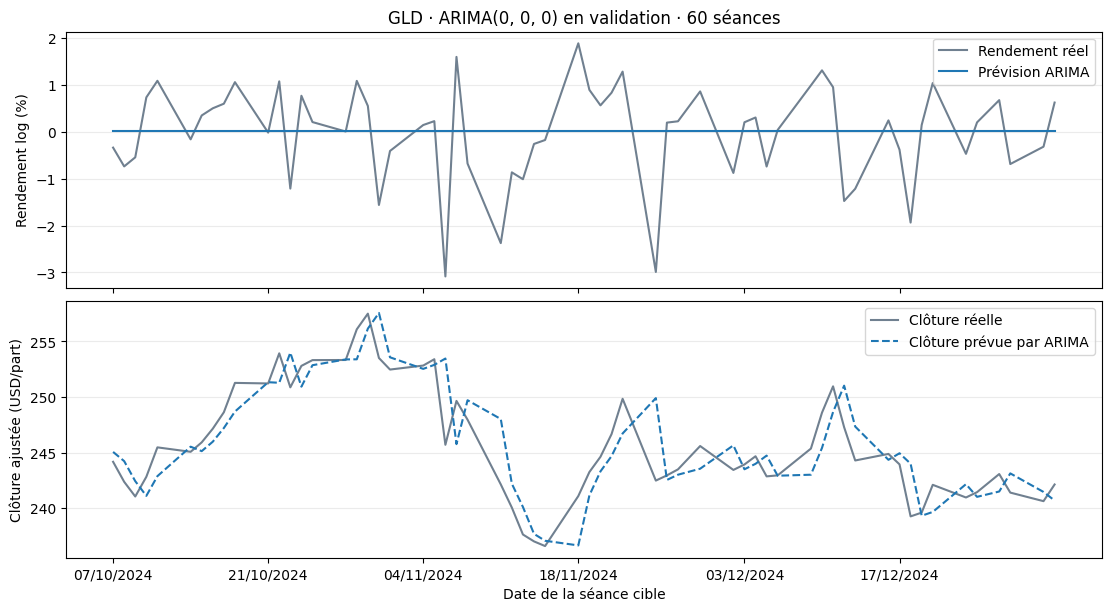

In [20]:
import matplotlib.dates as mdates

# Garder les rendements réels et ceux prévus par ARIMA en validation.
graphe = previsions.loc[
    previsions["Période"] == "Validation", ["Réel", "ARIMA"]
].copy()

# Pour chaque séance, récupérer sa clôture et celle de la séance précédente.
# On décale la série complète avant de sélectionner les 60 dernières séances.
graphe["cloture_reelle"] = df["Close"]
graphe["cloture_precedente"] = df["Close"].shift(1)
graphe = graphe.dropna().tail(60).copy()

# Convertir le rendement logarithmique prévu (%) en prix prévu (USD).
graphe["cloture_prevue"] = graphe["cloture_precedente"] * np.exp(graphe["ARIMA"] / 100)

fig, (ax_rendement, ax_prix) = plt.subplots(
    2, 1, figsize=(11, 6), sharex=True, layout="constrained"
)

# En haut : le modèle a-t-il bien prévu la variation du jour ?
ax_rendement.plot(graphe.index, graphe["Réel"], color="slategray", label="Rendement réel")
ax_rendement.plot(graphe.index, graphe["ARIMA"], color="tab:blue", label="Prévision ARIMA")
ax_rendement.set_ylabel("Rendement log (%)")
ax_rendement.set_title(f"GLD · ARIMA{ordre_arima} en validation · {len(graphe)} séances")

# En bas : à quel prix correspondait cette prévision pour chaque séance ?
ax_prix.plot(graphe.index, graphe["cloture_reelle"], color="slategray", label="Clôture réelle")
ax_prix.plot(
    graphe.index, graphe["cloture_prevue"],
    color="tab:blue", linestyle="--", label="Clôture prévue par ARIMA"
)
ax_prix.set_ylabel("Clôture ajustée (USD/part)")
ax_prix.set_xlabel("Date de la séance cible")

for axe in (ax_rendement, ax_prix):
    axe.legend(loc="upper right")
    axe.grid(axis="y", alpha=0.25)

ax_prix.set_xticks(graphe.index[::10])  # Affiche une date toutes les 10 séances
ax_prix.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%Y"))

plt.show()

### Verdict simple sur ARIMA

Une fois **l'ordre expliqué par l’ADF, l’ACF/PACF et l’AIC**, deux questions suffisent pour juger le résultat :

1. **Qualité du modèle** : ses résidus semblent-ils non autocorrélés ?
2. **Utilité prédictive** : ARIMA améliore-t-il la **MAE en validation** par rapport au modèle naïf ?

Le diagnostic statistique et la performance hors apprentissage sont **deux critères différents** : un bon diagnostic ne garantit pas une bonne prévision.

In [16]:
mae_arima = scores.loc["ARIMA", "MAE Validation"]
mae_naif = scores.loc["Naïf", "MAE Validation"]
p_lb = diagnostic_df.loc["ARIMA", "Ljung–Box p-value (train)"]

print(f"ARIMA{ordre_arima} | AIC apprentissage = {ajustes['ARIMA'].aic:.2f}")
print(f"MAE validation : ARIMA = {mae_arima:.4f} | Naïf = {mae_naif:.4f}")
print("Verdict prévision :", "ARIMA améliore la référence naïve en validation."
      if mae_arima < mae_naif else "ARIMA ne fait pas mieux que la référence naïve en validation.")
print("Verdict résidus :", "pas d'autocorrélation détectée (Ljung–Box, 5 %)."
      if p_lb >= 0.05 else "autocorrélation résiduelle détectée : modèle à interpréter avec prudence.")

ARIMA(0, 0, 0) | AIC apprentissage = 3321.38
MAE validation : ARIMA = 0.6800 | Naïf = 0.9854
Verdict prévision : ARIMA améliore la référence naïve en validation.
Verdict résidus : pas d'autocorrélation détectée (Ljung–Box, 5 %).


## 10. Justifier le choix final pour D03

Nous retenons **la plus faible MAE en validation**, puis vérifions la performance sur le **test final**. Nous examinons aussi si **Auto-ARIMA** sélectionne un meilleur modèle que l’ARIMA classique, puis si la saisonnalité (SARIMA) ou le volume retardé (SARIMAX) apportent un avantage par rapport à l’ARIMA traditionnel.

**Conclusion attendue :** si un modèle simple est meilleur, il n’y a aucune raison de retenir un modèle plus complexe. D03 vise un choix **argumenté par les données**, pas une promesse de prévision parfaite.

In [17]:
# Justification automatique du choix à partir des résultats calculés
print(f"Modèle retenu : {meilleur} — MAE la plus faible en validation.")
print(f"MAE validation : {scores.loc[meilleur, 'MAE Validation']:.4f} point(s) de %")
print(f"MAE test : {scores.loc[meilleur, 'MAE Test']:.4f} point(s) de %")

if meilleur == "Naïf":
    print("Conclusion : aucun modèle plus complexe ne fait mieux que la référence naïve en validation.")
else:
    ecart = 100 * (scores.loc["Naïf", "MAE Validation"] - scores.loc[meilleur, "MAE Validation"]) / scores.loc["Naïf", "MAE Validation"]
    print(f"Gain de MAE par rapport au naïf en validation : {ecart:.2f} %.")

if scores.loc["SARIMA", "MAE Validation"] < scores.loc["ARIMA", "MAE Validation"]:
    print("SARIMA améliore la MAE d'ARIMA en validation : l'hypothèse saisonnière mérite d'être considérée.")
else:
    print("SARIMA n'améliore pas la MAE d'ARIMA : l'ajout saisonnier n'est pas justifié par cette comparaison.")

if scores.loc["SARIMAX", "MAE Validation"] < scores.loc["ARIMA", "MAE Validation"]:
    print("SARIMAX obtient une MAE plus faible qu'ARIMA ; l'intérêt du volume retardé reste à confirmer.")
else:
    print("SARIMAX ne dépasse pas ARIMA en validation : aucun avantage clair de cette configuration.")

print("Limite : ces résultats évaluent la qualité des prévisions, pas la rentabilité d'une stratégie de trading.")

# Verdict complémentaire : approche manuelle vs approche automatique
mae_classique = scores.loc["ARIMA", "MAE Validation"]
mae_auto = scores.loc["Auto-ARIMA", "MAE Validation"]
print(f"\nARIMA classique {ordre_arima} : MAE validation = {mae_classique:.4f}")
print(f"Auto-ARIMA {ordre_auto} : MAE validation = {mae_auto:.4f}")
if mae_auto < mae_classique:
    print("Verdict : Auto-ARIMA prévoit mieux que l'ARIMA classique sur la validation.")
elif mae_auto > mae_classique:
    print("Verdict : l'ARIMA classique prévoit mieux qu'Auto-ARIMA sur la validation.")
else:
    print("Verdict : performances égales selon la MAE en validation.")


Modèle retenu : ARIMA — MAE la plus faible en validation.
MAE validation : 0.6800 point(s) de %
MAE test : 1.1441 point(s) de %
Gain de MAE par rapport au naïf en validation : 30.99 %.
SARIMA n'améliore pas la MAE d'ARIMA : l'ajout saisonnier n'est pas justifié par cette comparaison.
SARIMAX ne dépasse pas ARIMA en validation : aucun avantage clair de cette configuration.
Limite : ces résultats évaluent la qualité des prévisions, pas la rentabilité d'une stratégie de trading.

ARIMA classique (0, 0, 0) : MAE validation = 0.6800
Auto-ARIMA (0, 0, 0) : MAE validation = 0.6814
Verdict : l'ARIMA classique prévoit mieux qu'Auto-ARIMA sur la validation.


## 11. Prévoir les 5 prochaines séances avec ARIMA

Nous complétons les prédictions historiques par **5 prévisions futures**, produites avec **l'ARIMA traditionnel estimé sur le train** et les observations connues jusqu’à la dernière date du snapshot. Les coefficients ne sont pas réestimés.

L’**intervalle estimé à 95 %** illustre l’incertitude des prévisions. Les dates correspondent ici aux **jours ouvrés approximatifs** : les jours fériés de la Bourse américaine ne sont pas éliminés automatiquement. Ce graphique illustre ARIMA, **même si le meilleur modèle en validation est différent**.

Prévisions ARIMA : rendements journaliers (%)


,ARIMA,Borne basse (95 %),Borne haute (95 %)
Date,,,
2026-11-02,0.024,-1.75,1.799
2026-11-03,0.024,-1.75,1.799
2026-11-04,0.024,-1.75,1.799
2026-11-05,0.024,-1.75,1.799
2026-11-06,0.024,-1.75,1.799


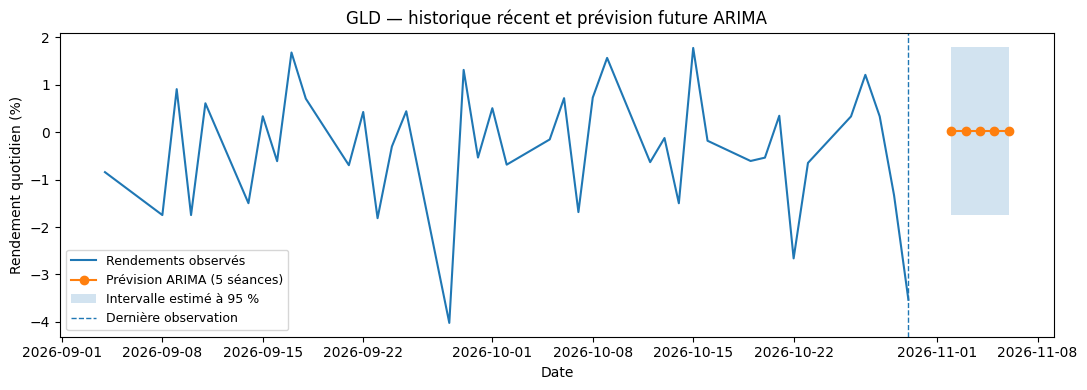

In [18]:
# Prévision future : aucun rendement futur n'est utilisé
historique_arima = ajustes["ARIMA"].apply(y, refit=False)
future = historique_arima.get_forecast(steps=5)
dates_futures = pd.bdate_range(df.index[-1] + pd.offsets.BDay(1), periods=5)
intervalles = np.asarray(future.conf_int(alpha=0.05))

previsions_futures = pd.DataFrame({
    "ARIMA": np.asarray(future.predicted_mean),
    "Borne basse (95 %)": intervalles[:, 0],
    "Borne haute (95 %)": intervalles[:, 1],
}, index=dates_futures)
previsions_futures.index.name = "Date"
print("Prévisions ARIMA : rendements journaliers (%)")
display(previsions_futures.round(3))

plt.figure(figsize=(11, 4))
plt.plot(df.index[-40:], df["rendement"].tail(40), label="Rendements observés")
plt.plot(previsions_futures.index, previsions_futures["ARIMA"],
         marker="o", label="Prévision ARIMA (5 séances)")
plt.fill_between(previsions_futures.index,
                 previsions_futures["Borne basse (95 %)"],
                 previsions_futures["Borne haute (95 %)"],
                 alpha=0.2, label="Intervalle estimé à 95 %")
plt.axvline(df.index[-1], linestyle="--", linewidth=1, label="Dernière observation")
plt.title("GLD — historique récent et prévision future ARIMA")
plt.ylabel("Rendement quotidien (%)")
plt.xlabel("Date")
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 12. Conserver les preuves du livrable

Les tableaux enregistrés dans `reports/d03/` rendent D03 **reproductible et vérifiable** :
- `previsions_d03.csv` : prévisions datées du naïf, d'ARIMA classique, d'Auto-ARIMA, de SARIMA et de SARIMAX ;
- `comparaison_d03.csv` : MAE et RMSE en validation et en test ;
- `diagnostics_d03.csv` : tests de Ljung–Box ;
- `previsions_futures_arima.csv` : cinq prévisions futures ARIMA avec intervalle estimé.

**Bilan :** identification par stationnarité et ACF/PACF, comparaison avec Auto-ARIMA, choix documenté, diagnostics et comparaison réellement hors apprentissage. Ces résultats mesurent la capacité de prédiction, pas la rentabilité d’une stratégie.

In [19]:
sortie = ROOT / "reports" / "d03"
sortie.mkdir(parents=True, exist_ok=True)
previsions.to_csv(sortie / "previsions_d03.csv", encoding="utf-8-sig")
scores.to_csv(sortie / "comparaison_d03.csv", encoding="utf-8-sig")
pd.DataFrame(diagnostics).to_csv(sortie / "diagnostics_d03.csv", index=False, encoding="utf-8-sig")
previsions_futures.to_csv(sortie / "previsions_futures_arima.csv", encoding="utf-8-sig")
print("Fichiers sauvegardés dans :", sortie.relative_to(ROOT))

Fichiers sauvegardés dans : reports\d03
